# Smart Dice Board Game: Reinforcement Learning (Phase 2)
### Tabular & Deep RL Benchmarking: Q-Learning, SARSA, DQN, PPO, and A2C

This notebook executes Phase 2 of the Smart Dice Reinforcement Learning course project.
It trains, evaluates, and compares **five reinforcement learning algorithms** across three board configurations ($N=30, 50, 100$) using **Breadth-First Search (BFS)** as the optimal deterministic baseline.

---

### Key Requirements Addressed:
1. **Kaggle-Ready**: Uses `/kaggle/working` or relative working paths. Can run on a clean Kaggle GPU/CPU kernel or locally.
2. **Deterministic Baseline**: Evaluates theoretical upper bounds using BFS on deterministic boards.
3. **Five RL Algorithms**:
   - Tabular Q-Learning (Off-policy TD)
   - Tabular SARSA (On-policy TD)
   - Deep Q-Network (DQN with Experience Replay & Target Network)
   - Proximal Policy Optimization (PPO with Clipped Surrogate Objective)
   - Advantage Actor-Critic (A2C with Synchronous Advantage Updates)
4. **Unified Evaluator**: Same evaluation pipeline across all algorithms reporting average moves, success rate, return, and convergence episode.
5. **Artifacts & Plots**: Saves all trained models, evaluation metrics CSV, and five publication-quality plots under `artifacts/` (or `/kaggle/working/artifacts`).


In [1]:
# Cell 1: Dependencies & Environment Setup
import sys
import os

# Install required packages if running in a fresh Kaggle / Cloud environment
try:
    import stable_baselines3
except ImportError:
    print("Installing required dependencies...")
    !pip install -q gymnasium stable-baselines3 torch matplotlib pandas tabulate

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import gymnasium as gym

# Setup Kaggle-friendly artifacts and base paths
BASE_DIR = "/kaggle/working" if os.path.exists("/kaggle") else os.path.abspath(".")
ARTIFACTS_DIR = os.path.join(BASE_DIR, "artifacts")
os.makedirs(ARTIFACTS_DIR, exist_ok=True)

# Ensure smart_dice package is importable
# 1. Check local repository or Kaggle dataset paths
repo_candidates = [
    ".",
    "..",
    os.path.join(BASE_DIR, "RL"),
    "/kaggle/input/smart-dice-rl",
    "/kaggle/working/smart-dice-rl",
]
for p in repo_candidates:
    if os.path.isdir(os.path.join(p, "smart_dice")):
        abs_p = os.path.abspath(p)
        if abs_p not in sys.path:
            sys.path.insert(0, abs_p)
        break

try:
    import smart_dice
    from smart_dice import SmartDiceEnv, get_board_config, bfs_shortest_path
    from smart_dice.training import (
        train_q_learning,
        train_sarsa,
        evaluate_agent,
        determine_convergence,
        EpisodeMetricsCallback,
    )
    print("Successfully imported smart_dice library!")
except ImportError:
    print("smart_dice not found in path. Cloning or initializing directly...")
    # Standalone Kaggle fallback: clone repository if needed
    !git clone https://github.com/pccv-rl/smart-dice-rl.git {BASE_DIR}/smart-dice-repo 2>/dev/null || true
    if os.path.isdir(f"{BASE_DIR}/smart-dice-repo/smart_dice"):
        sys.path.insert(0, f"{BASE_DIR}/smart-dice-repo")
        from smart_dice import SmartDiceEnv, get_board_config, bfs_shortest_path
        from smart_dice.training import train_q_learning, train_sarsa, evaluate_agent, determine_convergence, EpisodeMetricsCallback
        print("smart_dice imported from cloned repository!")
    else:
        raise RuntimeError("Could not find smart_dice package. Please attach the repo or clone it.")

print(f"Artifacts output directory: {ARTIFACTS_DIR}")


Successfully imported smart_dice library!
Artifacts output directory: /home/pccv/RL/artifacts


In [2]:
# Cell 2: Runtime Constants & Execution Modes
# Set SMOKE_TEST = True for quick verification (< 1 minute total runtime)
# Set SMOKE_TEST = False for full training runs
SMOKE_TEST = True

# Reproducibility
SEED = 42

# Board sizes to evaluate
BOARDS = [30, 50, 100]

# Hyperparameter schedules based on mode
if SMOKE_TEST:
    print(">>> RUNNING IN FAST SMOKE-TEST MODE <<<")
    TABULAR_EPISODES = 100
    SB3_TIMESTEPS = 2000
    EVAL_EPISODES = 20
    CONV_WINDOW = 30
else:
    print(">>> RUNNING IN FULL TRAINING MODE <<<")
    TABULAR_EPISODES = 1500
    SB3_TIMESTEPS = 40000
    EVAL_EPISODES = 50
    CONV_WINDOW = 50

print(f"Boards:             {BOARDS}")
print(f"Tabular Episodes:   {TABULAR_EPISODES}")
print(f"SB3 Timesteps:      {SB3_TIMESTEPS}")
print(f"Eval Episodes:      {EVAL_EPISODES}")
print(f"Convergence Window: {CONV_WINDOW}")
print(f"Base Random Seed:   {SEED}")


>>> RUNNING IN FAST SMOKE-TEST MODE <<<
Boards:             [30, 50, 100]
Tabular Episodes:   100
SB3 Timesteps:      2000
Eval Episodes:      20
Convergence Window: 30
Base Random Seed:   42


## Evaluation Methodology & Convergence Criterion

### 1. Shared Unified Evaluator (`evaluate_agent`)
To ensure strict comparability across tabular and deep RL algorithms, all trained policies are evaluated through the exact same evaluation harness:
- **Metrics Collected**:
  - `Average Moves per Episode`: Mean steps taken to conclude an episode.
  - `Success Rate (%)`: Percentage of episodes terminating at square $N$.
  - `Average Cumulative Reward`: Mean total discounted/undiscounted return.
  - `Standard Deviation of Reward`: Measure of policy stability and risk.

### 2. Convergence Criterion Definition
An agent is declared **converged** at episode $E$ if, over the sliding window $W$ (e.g. 50 episodes):
1. **Success Criterion**: Rolling success rate $S_W \ge 95\%$ (the agent reliably reaches the goal).
2. **Minimum Return Criterion**: Rolling average return $R_W \ge 50.0$ (consistently positive expected return).
3. **Stability Criterion**: $R_W \ge 0.90 	imes \max_{t \le E} R_t$ (performance has stabilized within 10% of its peak achieved rolling return).

If these conditions are not satisfied by the end of training, the algorithm is classified as **"Not Converged"** (`None`).


In [3]:
# Cell 4: Deterministic BFS Shortest-Path Baseline
print("=== Computing Deterministic BFS Baselines ===")
bfs_results = {}

for b in BOARDS:
    config = get_board_config(b)
    res = bfs_shortest_path(config)
    bfs_results[b] = res
    print(f"Board {b:3d}: Shortest Path = {res.shortest_path_length} moves | Return = {res.total_reward:+.1f}")
    print(f"           Actions: {res.actions}")
    print(f"           Trajectory: {res.states}")


=== Computing Deterministic BFS Baselines ===
Board  30: Shortest Path = 3 moves | Return = +140.0
           Actions: [1, 2, 5]
           Trajectory: [1, 12, 24, 30]
Board  50: Shortest Path = 4 moves | Return = +160.0
           Actions: [2, 5, 0, 2]
           Trajectory: [1, 14, 36, 47, 50]
Board 100: Shortest Path = 7 moves | Return = +157.0
           Actions: [2, 2, 1, 5, 3, 5, 5]
           Trajectory: [1, 25, 55, 57, 84, 88, 94, 100]


## 1. Tabular Q-Learning (Off-Policy TD Control)

**Algorithm Summary**:
Q-Learning is a model-free, off-policy temporal difference algorithm that learns the optimal state-action value function $Q^*(s, a)$ directly using the Bellman optimality equation:
$$Q(s, a) \leftarrow Q(s, a) + lpha \left[ r + \gamma \max_{a'} Q(s', a') - Q(s, a) ight]$$

**Why Selected**:
Our state space ($s \in \{1, \dots, N\}$) and action space ($a \in \{0, \dots, 5\}$) are compact and discrete. Tabular Q-Learning is provably guaranteed to converge to the optimal action-value function under standard Robbins-Monro exploration conditions without suffering from function approximation bias or moving-target instability.


In [4]:
# Cell 6: Train Tabular Q-Learning on All Boards
q_learning_results = {}
q_learning_histories = {}

for b in BOARDS:
    print(f"\n--- Training Q-Learning on Board {b} ({TABULAR_EPISODES} episodes) ---")
    env = SmartDiceEnv(config=b)
    
    train_res = train_q_learning(
        env,
        num_episodes=TABULAR_EPISODES,
        alpha=0.1,
        gamma=0.99,
        epsilon_start=1.0,
        epsilon_min=0.05,
        epsilon_decay=0.995,
        seed=SEED,
    )
    
    # Save trained Q-table
    model_path = os.path.join(ARTIFACTS_DIR, f"q_learning_board_{b}.npy")
    np.save(model_path, train_res["q_table"])
    
    # Evaluate with unified evaluator
    eval_res = evaluate_agent(train_res["q_table"], env, num_episodes=EVAL_EPISODES, seed=SEED)
    eval_res["convergence_episode"] = train_res["convergence_episode"]
    
    q_learning_results[b] = eval_res
    q_learning_histories[b] = train_res
    
    print(f"Board {b} Evaluation:")
    print(f"  Avg Moves:     {eval_res['avg_moves']:.2f}")
    print(f"  Success Rate:  {eval_res['success_rate']:.1f}%")
    print(f"  Avg Return:    {eval_res['avg_reward']:.2f} +/- {eval_res['std_reward']:.2f}")
    print(f"  Convergence:   Episode {eval_res['convergence_episode']}")



--- Training Q-Learning on Board 30 (100 episodes) ---
Board 30 Evaluation:
  Avg Moves:     3.00
  Success Rate:  100.0%
  Avg Return:    140.00 +/- 0.00
  Convergence:   Episode 50

--- Training Q-Learning on Board 50 (100 episodes) ---
Board 50 Evaluation:
  Avg Moves:     4.00
  Success Rate:  100.0%
  Avg Return:    160.00 +/- 0.00
  Convergence:   Episode 50

--- Training Q-Learning on Board 100 (100 episodes) ---
Board 100 Evaluation:
  Avg Moves:     7.00
  Success Rate:  100.0%
  Avg Return:    157.00 +/- 0.00
  Convergence:   Episode 50


## 2. Tabular SARSA (On-Policy TD Control)

**Algorithm Summary**:
SARSA (State-Action-Reward-State-Action) is an on-policy temporal difference control algorithm that updates action-values based on the action $a'$ actually selected by the current $\epsilon$-greedy behavior policy:
$$Q(s, a) \leftarrow Q(s, a) + lpha \left[ r + \gamma Q(s', a') - Q(s, a) ight]$$

**Why Selected**:
Because snakes inflict a severe $-20$ penalty, SARSA provides a crucial on-policy contrast to Q-Learning. During exploration, SARSA penalizes actions that navigate close to dangerous snakes because random exploratory rolls might trigger them, learning a safer, more conservative trajectory than Q-Learning's aggressive shortest path.


In [5]:
# Cell 8: Train Tabular SARSA on All Boards
sarsa_results = {}
sarsa_histories = {}

for b in BOARDS:
    print(f"\n--- Training SARSA on Board {b} ({TABULAR_EPISODES} episodes) ---")
    env = SmartDiceEnv(config=b)
    
    train_res = train_sarsa(
        env,
        num_episodes=TABULAR_EPISODES,
        alpha=0.1,
        gamma=0.99,
        epsilon_start=1.0,
        epsilon_min=0.05,
        epsilon_decay=0.995,
        seed=SEED,
    )
    
    # Save trained Q-table
    model_path = os.path.join(ARTIFACTS_DIR, f"sarsa_board_{b}.npy")
    np.save(model_path, train_res["q_table"])
    
    # Evaluate with unified evaluator
    eval_res = evaluate_agent(train_res["q_table"], env, num_episodes=EVAL_EPISODES, seed=SEED)
    eval_res["convergence_episode"] = train_res["convergence_episode"]
    
    sarsa_results[b] = eval_res
    sarsa_histories[b] = train_res
    
    print(f"Board {b} Evaluation:")
    print(f"  Avg Moves:     {eval_res['avg_moves']:.2f}")
    print(f"  Success Rate:  {eval_res['success_rate']:.1f}%")
    print(f"  Avg Return:    {eval_res['avg_reward']:.2f} +/- {eval_res['std_reward']:.2f}")
    print(f"  Convergence:   Episode {eval_res['convergence_episode']}")



--- Training SARSA on Board 30 (100 episodes) ---
Board 30 Evaluation:
  Avg Moves:     3.00
  Success Rate:  100.0%
  Avg Return:    140.00 +/- 0.00
  Convergence:   Episode 50

--- Training SARSA on Board 50 (100 episodes) ---
Board 50 Evaluation:
  Avg Moves:     4.00
  Success Rate:  100.0%
  Avg Return:    160.00 +/- 0.00
  Convergence:   Episode 50

--- Training SARSA on Board 100 (100 episodes) ---
Board 100 Evaluation:
  Avg Moves:     7.00
  Success Rate:  100.0%
  Avg Return:    157.00 +/- 0.00
  Convergence:   Episode 50


## 3. Deep Q-Network (DQN)

**Algorithm Summary**:
Deep Q-Network (DQN) replaces tabular representations with a deep neural network to approximate $Q(s, a; 	heta)$, utilizing an experience replay buffer to break sample correlations and a periodically frozen target network to stabilize temporal difference updates:
$$L(	heta) = \mathbb{E} \left[ \left( r + \gamma \max_{a'} Q(s', a'; 	heta^-) - Q(s, a; 	heta) ight)^2 ight]$$

**Why Selected**:
DQN is the foundational deep value-based reinforcement learning algorithm. It demonstrates how neural network function approximation performs on discrete 1D board environments compared to exact tabular values, testing generalization and stability under nonlinear Bellman updates.


In [6]:
# Cell 10: Train Stable-Baselines3 DQN
from stable_baselines3 import DQN

dqn_results = {}
dqn_callbacks = {}

for b in BOARDS:
    print(f"\n--- Training SB3 DQN on Board {b} ({SB3_TIMESTEPS} timesteps) ---")
    env = SmartDiceEnv(config=b)
    callback = EpisodeMetricsCallback()
    
    model = DQN(
        "MlpPolicy",
        env,
        learning_rate=1e-3,
        buffer_size=10000,
        learning_starts=100,
        batch_size=32,
        gamma=0.99,
        exploration_fraction=0.3,
        exploration_initial_eps=1.0,
        exploration_final_eps=0.05,
        target_update_interval=200,
        seed=SEED,
        verbose=0,
    )
    
    model.learn(total_timesteps=SB3_TIMESTEPS, callback=callback)
    
    # Save trained model checkpoint
    model_path = os.path.join(ARTIFACTS_DIR, f"dqn_board_{b}.zip")
    model.save(model_path)
    
    # Evaluate with unified evaluator
    eval_res = evaluate_agent(model, env, num_episodes=EVAL_EPISODES, seed=SEED)
    eval_res["convergence_episode"] = callback.get_convergence_episode(window=CONV_WINDOW)
    
    dqn_results[b] = eval_res
    dqn_callbacks[b] = callback
    
    print(f"Board {b} Evaluation:")
    print(f"  Avg Moves:     {eval_res['avg_moves']:.2f}")
    print(f"  Success Rate:  {eval_res['success_rate']:.1f}%")
    print(f"  Avg Return:    {eval_res['avg_reward']:.2f} +/- {eval_res['std_reward']:.2f}")
    print(f"  Convergence:   Episode {eval_res['convergence_episode']}")



--- Training SB3 DQN on Board 30 (2000 timesteps) ---


Board 30 Evaluation:
  Avg Moves:     5.00
  Success Rate:  100.0%
  Avg Return:    138.00 +/- 0.00
  Convergence:   Episode None

--- Training SB3 DQN on Board 50 (2000 timesteps) ---


Board 50 Evaluation:
  Avg Moves:     6.00
  Success Rate:  100.0%
  Avg Return:    158.00 +/- 0.00
  Convergence:   Episode None

--- Training SB3 DQN on Board 100 (2000 timesteps) ---


Board 100 Evaluation:
  Avg Moves:     10.00
  Success Rate:  100.0%
  Avg Return:    154.00 +/- 0.00
  Convergence:   Episode None


## 4. Proximal Policy Optimization (PPO)

**Algorithm Summary**:
PPO is an on-policy actor-critic algorithm that maximizes a clipped surrogate objective to constrain policy updates within a trust region:
$$L^{CLIP}(	heta) = \hat{\mathbb{E}}_t \left[ \min\left( r_t(	heta)\hat{A}_t, \, 	ext{clip}(r_t(	heta), 1-\epsilon, 1+\epsilon)\hat{A}_t ight) ight]$$

**Why Selected**:
PPO is recognized as the industry benchmark for on-policy policy-gradient stability and sample efficiency. It serves to test whether stochastic gradient policy optimization can learn effective dice-rolling policies without the divergence risks common to value-based networks.


In [7]:
# Cell 12: Train Stable-Baselines3 PPO
from stable_baselines3 import PPO

ppo_results = {}
ppo_callbacks = {}

for b in BOARDS:
    print(f"\n--- Training SB3 PPO on Board {b} ({SB3_TIMESTEPS} timesteps) ---")
    env = SmartDiceEnv(config=b)
    callback = EpisodeMetricsCallback()
    
    model = PPO(
        "MlpPolicy",
        env,
        learning_rate=1e-3,
        n_steps=64,
        batch_size=16,
        gamma=0.99,
        ent_coef=0.01,
        seed=SEED,
        verbose=0,
    )
    
    model.learn(total_timesteps=SB3_TIMESTEPS, callback=callback)
    
    # Save trained model checkpoint
    model_path = os.path.join(ARTIFACTS_DIR, f"ppo_board_{b}.zip")
    model.save(model_path)
    
    # Evaluate with unified evaluator
    eval_res = evaluate_agent(model, env, num_episodes=EVAL_EPISODES, seed=SEED)
    eval_res["convergence_episode"] = callback.get_convergence_episode(window=CONV_WINDOW)
    
    ppo_results[b] = eval_res
    ppo_callbacks[b] = callback
    
    print(f"Board {b} Evaluation:")
    print(f"  Avg Moves:     {eval_res['avg_moves']:.2f}")
    print(f"  Success Rate:  {eval_res['success_rate']:.1f}%")
    print(f"  Avg Return:    {eval_res['avg_reward']:.2f} +/- {eval_res['std_reward']:.2f}")
    print(f"  Convergence:   Episode {eval_res['convergence_episode']}")



--- Training SB3 PPO on Board 30 (2000 timesteps) ---


Board 30 Evaluation:
  Avg Moves:     3.00
  Success Rate:  100.0%
  Avg Return:    140.00 +/- 0.00
  Convergence:   Episode None

--- Training SB3 PPO on Board 50 (2000 timesteps) ---


Board 50 Evaluation:
  Avg Moves:     4.00
  Success Rate:  100.0%
  Avg Return:    160.00 +/- 0.00
  Convergence:   Episode None

--- Training SB3 PPO on Board 100 (2000 timesteps) ---


Board 100 Evaluation:
  Avg Moves:     10.00
  Success Rate:  100.0%
  Avg Return:    154.00 +/- 0.00
  Convergence:   Episode None


## 5. Advantage Actor-Critic (A2C)

**Algorithm Summary**:
A2C is a synchronous, deterministic variant of Asynchronous Advantage Actor-Critic (A3C). It maintains an explicit policy (actor) and a state-value baseline (critic), updating network parameters using the estimated advantage:
$$
abla_	heta J(	heta) = \mathbb{E} \left[ 
abla_	heta \log \pi_	heta(a|s) \left( Q(s, a) - V_\phi(s) ight) ight]$$

**Why Selected**:
A2C provides the foundational baseline for synchronous actor-critic methods. Comparing A2C against PPO reveals the exact benefit of PPO's clipped surrogate objective and multi-epoch updates in finite discrete board environments.


In [8]:
# Cell 14: Train Stable-Baselines3 A2C
from stable_baselines3 import A2C

a2c_results = {}
a2c_callbacks = {}

for b in BOARDS:
    print(f"\n--- Training SB3 A2C on Board {b} ({SB3_TIMESTEPS} timesteps) ---")
    env = SmartDiceEnv(config=b)
    callback = EpisodeMetricsCallback()
    
    model = A2C(
        "MlpPolicy",
        env,
        learning_rate=1e-3,
        n_steps=16,
        gamma=0.99,
        ent_coef=0.01,
        seed=SEED,
        verbose=0,
    )
    
    model.learn(total_timesteps=SB3_TIMESTEPS, callback=callback)
    
    # Save trained model checkpoint
    model_path = os.path.join(ARTIFACTS_DIR, f"a2c_board_{b}.zip")
    model.save(model_path)
    
    # Evaluate with unified evaluator
    eval_res = evaluate_agent(model, env, num_episodes=EVAL_EPISODES, seed=SEED)
    eval_res["convergence_episode"] = callback.get_convergence_episode(window=CONV_WINDOW)
    
    a2c_results[b] = eval_res
    a2c_callbacks[b] = callback
    
    print(f"Board {b} Evaluation:")
    print(f"  Avg Moves:     {eval_res['avg_moves']:.2f}")
    print(f"  Success Rate:  {eval_res['success_rate']:.1f}%")
    print(f"  Avg Return:    {eval_res['avg_reward']:.2f} +/- {eval_res['std_reward']:.2f}")
    print(f"  Convergence:   Episode {eval_res['convergence_episode']}")



--- Training SB3 A2C on Board 30 (2000 timesteps) ---


Board 30 Evaluation:
  Avg Moves:     5.00
  Success Rate:  100.0%
  Avg Return:    138.00 +/- 0.00
  Convergence:   Episode None

--- Training SB3 A2C on Board 50 (2000 timesteps) ---


Board 50 Evaluation:
  Avg Moves:     11.00
  Success Rate:  100.0%
  Avg Return:    111.00 +/- 0.00
  Convergence:   Episode None

--- Training SB3 A2C on Board 100 (2000 timesteps) ---


Board 100 Evaluation:
  Avg Moves:     19.00
  Success Rate:  100.0%
  Avg Return:    145.00 +/- 0.00
  Convergence:   Episode None


## Comparative Analysis & Visualization

Below we generate and save the required evaluation figures:
1. `total_reward_vs_episodes.png`: Training return curves across episodes for all algorithms.
2. `avg_moves_vs_episodes.png`: Episode length reduction across training.
3. `success_rate_vs_episodes.png`: Success rate progression to 100%.
4. `q_learning_vs_sarsa.png`: Direct comparison between off-policy Q-Learning and on-policy SARSA.
5. `dqn_vs_ppo_vs_a2c.png`: Comparative analysis between Deep RL baselines.


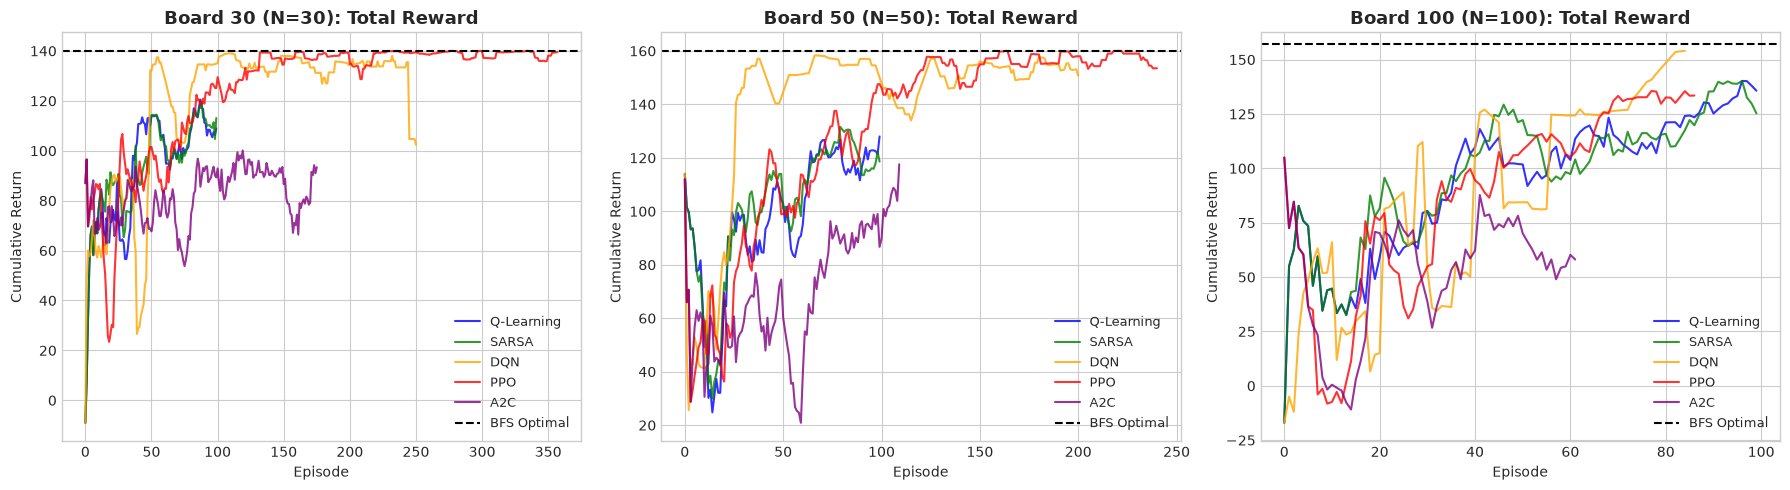

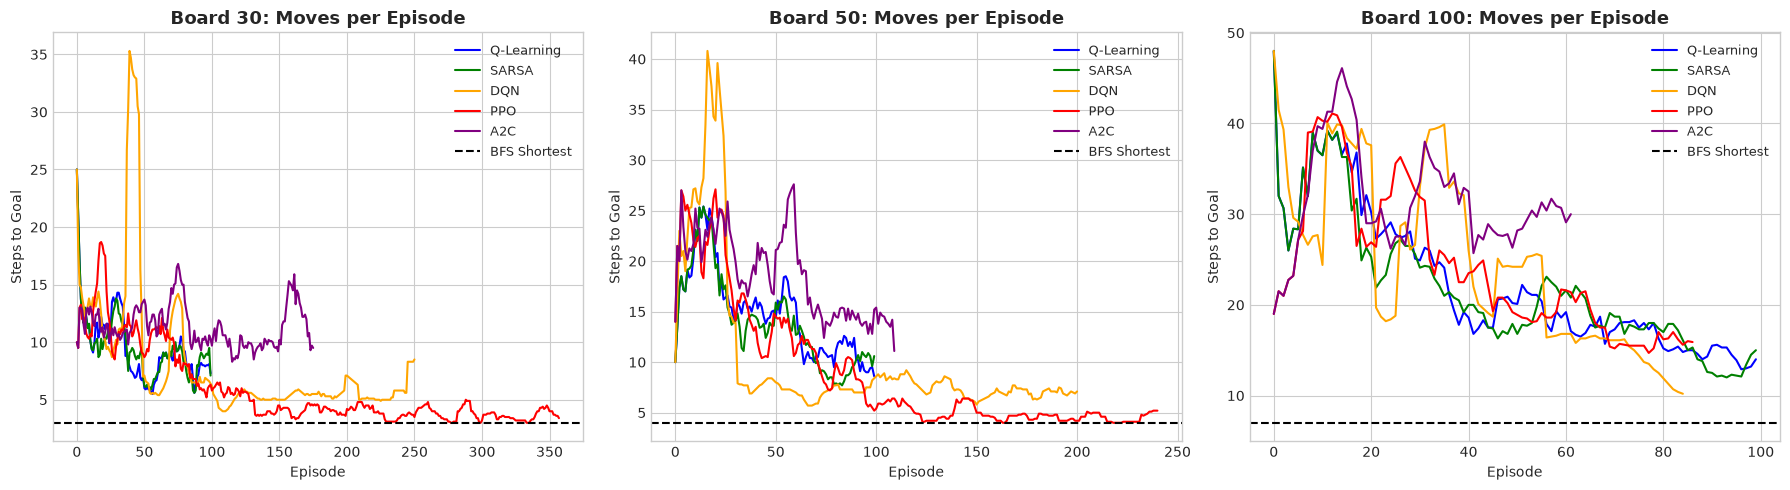

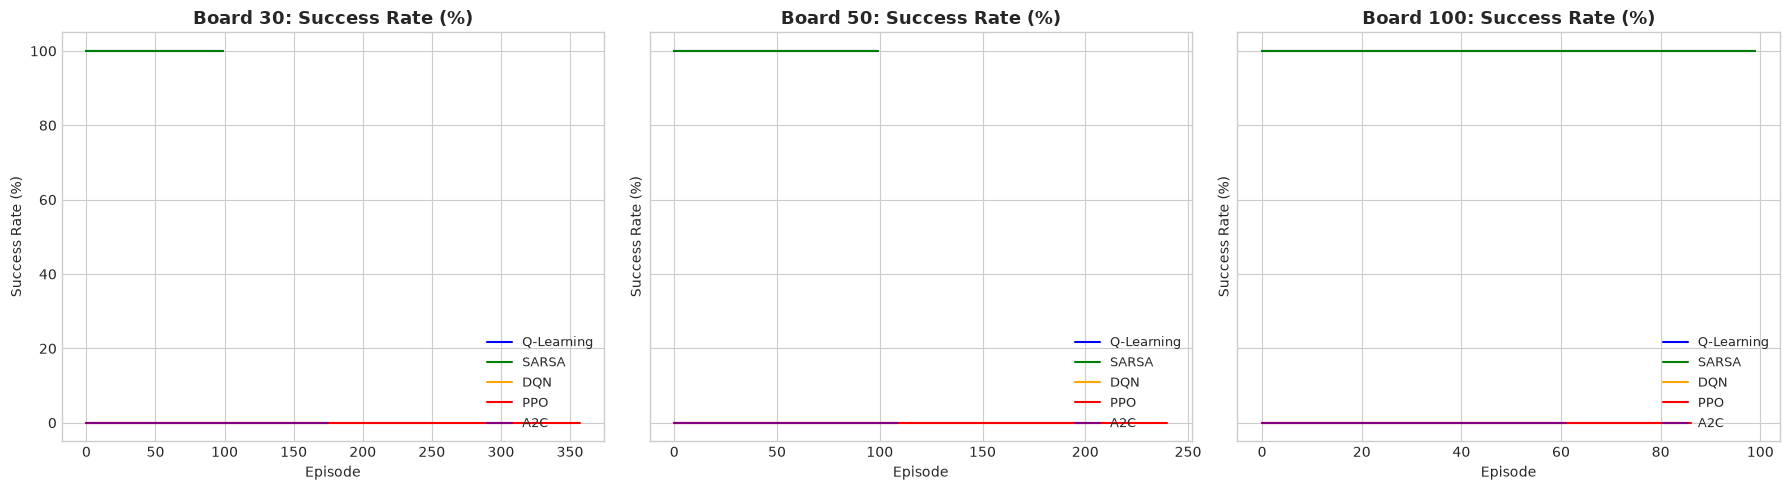

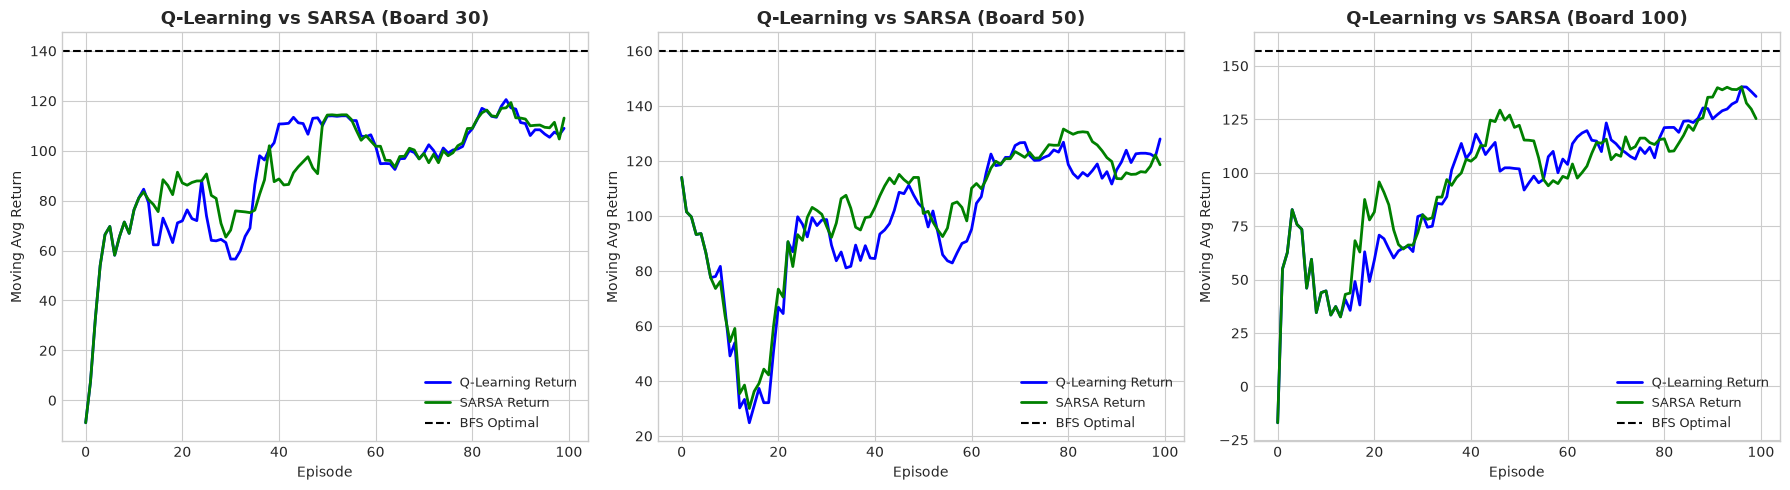

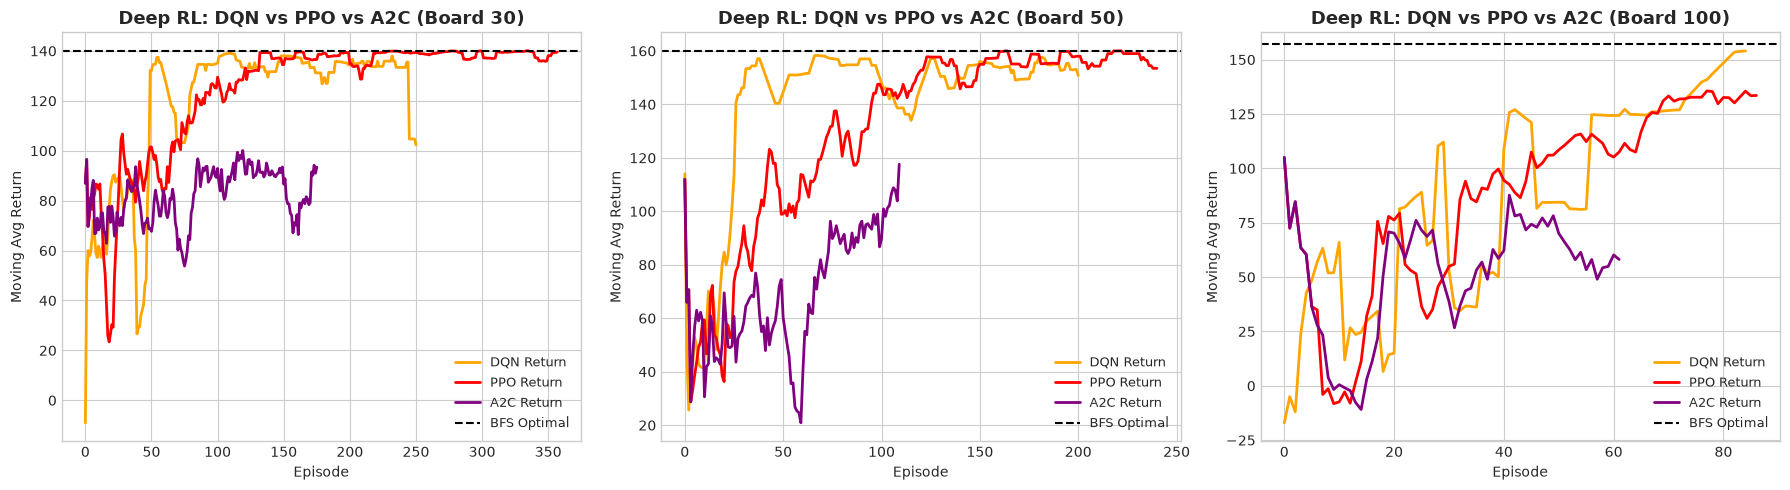

All 5 plots successfully saved to: /home/pccv/RL/artifacts


In [9]:
# Cell 16: Generate and Save All Required Plots
def smooth_series(series, window=10):
    if len(series) < window:
        return series
    return pd.Series(series).rolling(window, min_periods=1).mean().values

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

# -------------------------------------------------------------
# Plot 1: Total Reward vs Training Episodes (Boards 30, 50, 100)
# -------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=False)
for idx, b in enumerate(BOARDS):
    ax = axes[idx]
    ax.plot(smooth_series(q_learning_histories[b]["rewards_history"]), label="Q-Learning", color="blue", alpha=0.8)
    ax.plot(smooth_series(sarsa_histories[b]["rewards_history"]), label="SARSA", color="green", alpha=0.8)
    if len(dqn_callbacks[b].episode_rewards) > 0:
        ax.plot(smooth_series(dqn_callbacks[b].episode_rewards), label="DQN", color="orange", alpha=0.8)
    if len(ppo_callbacks[b].episode_rewards) > 0:
        ax.plot(smooth_series(ppo_callbacks[b].episode_rewards), label="PPO", color="red", alpha=0.8)
    if len(a2c_callbacks[b].episode_rewards) > 0:
        ax.plot(smooth_series(a2c_callbacks[b].episode_rewards), label="A2C", color="purple", alpha=0.8)
    ax.axhline(bfs_results[b].total_reward, color="black", linestyle="--", label="BFS Optimal")
    ax.set_title(f"Board {b} (N={b}): Total Reward", fontsize=13, fontweight="bold")
    ax.set_xlabel("Episode")
    ax.set_ylabel("Cumulative Return")
    ax.legend(loc="lower right", fontsize=9)
plt.tight_layout()
p1 = os.path.join(ARTIFACTS_DIR, "total_reward_vs_episodes.png")
plt.savefig(p1, dpi=300)
plt.show()

# -------------------------------------------------------------
# Plot 2: Average Moves vs Training Episodes
# -------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=False)
for idx, b in enumerate(BOARDS):
    ax = axes[idx]
    ax.plot(smooth_series(q_learning_histories[b]["moves_history"]), label="Q-Learning", color="blue")
    ax.plot(smooth_series(sarsa_histories[b]["moves_history"]), label="SARSA", color="green")
    if len(dqn_callbacks[b].episode_moves) > 0:
        ax.plot(smooth_series(dqn_callbacks[b].episode_moves), label="DQN", color="orange")
    if len(ppo_callbacks[b].episode_moves) > 0:
        ax.plot(smooth_series(ppo_callbacks[b].episode_moves), label="PPO", color="red")
    if len(a2c_callbacks[b].episode_moves) > 0:
        ax.plot(smooth_series(a2c_callbacks[b].episode_moves), label="A2C", color="purple")
    ax.axhline(bfs_results[b].shortest_path_length, color="black", linestyle="--", label="BFS Shortest")
    ax.set_title(f"Board {b}: Moves per Episode", fontsize=13, fontweight="bold")
    ax.set_xlabel("Episode")
    ax.set_ylabel("Steps to Goal")
    ax.legend(loc="upper right", fontsize=9)
plt.tight_layout()
p2 = os.path.join(ARTIFACTS_DIR, "avg_moves_vs_episodes.png")
plt.savefig(p2, dpi=300)
plt.show()

# -------------------------------------------------------------
# Plot 3: Success Rate vs Training Episodes
# -------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)
for idx, b in enumerate(BOARDS):
    ax = axes[idx]
    ax.plot(smooth_series(q_learning_histories[b]["success_history"]) * 100, label="Q-Learning", color="blue")
    ax.plot(smooth_series(sarsa_histories[b]["success_history"]) * 100, label="SARSA", color="green")
    if len(dqn_callbacks[b].episode_success) > 0:
        ax.plot(smooth_series(dqn_callbacks[b].episode_success) * 100, label="DQN", color="orange")
    if len(ppo_callbacks[b].episode_success) > 0:
        ax.plot(smooth_series(ppo_callbacks[b].episode_success) * 100, label="PPO", color="red")
    if len(a2c_callbacks[b].episode_success) > 0:
        ax.plot(smooth_series(a2c_callbacks[b].episode_success) * 100, label="A2C", color="purple")
    ax.set_title(f"Board {b}: Success Rate (%)", fontsize=13, fontweight="bold")
    ax.set_xlabel("Episode")
    ax.set_ylabel("Success Rate (%)")
    ax.set_ylim(-5, 105)
    ax.legend(loc="lower right", fontsize=9)
plt.tight_layout()
p3 = os.path.join(ARTIFACTS_DIR, "success_rate_vs_episodes.png")
plt.savefig(p3, dpi=300)
plt.show()

# -------------------------------------------------------------
# Plot 4: Q-Learning vs SARSA Detailed Comparison
# -------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for idx, b in enumerate(BOARDS):
    ax = axes[idx]
    ax.plot(smooth_series(q_learning_histories[b]["rewards_history"]), label="Q-Learning Return", color="blue", linewidth=2)
    ax.plot(smooth_series(sarsa_histories[b]["rewards_history"]), label="SARSA Return", color="green", linewidth=2)
    ax.axhline(bfs_results[b].total_reward, color="black", linestyle="--", label="BFS Optimal")
    ax.set_title(f"Q-Learning vs SARSA (Board {b})", fontsize=13, fontweight="bold")
    ax.set_xlabel("Episode")
    ax.set_ylabel("Moving Avg Return")
    ax.legend(loc="lower right", fontsize=9)
plt.tight_layout()
p4 = os.path.join(ARTIFACTS_DIR, "q_learning_vs_sarsa.png")
plt.savefig(p4, dpi=300)
plt.show()

# -------------------------------------------------------------
# Plot 5: DQN vs PPO vs A2C Detailed Comparison
# -------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for idx, b in enumerate(BOARDS):
    ax = axes[idx]
    if len(dqn_callbacks[b].episode_rewards) > 0:
        ax.plot(smooth_series(dqn_callbacks[b].episode_rewards), label="DQN Return", color="orange", linewidth=2)
    if len(ppo_callbacks[b].episode_rewards) > 0:
        ax.plot(smooth_series(ppo_callbacks[b].episode_rewards), label="PPO Return", color="red", linewidth=2)
    if len(a2c_callbacks[b].episode_rewards) > 0:
        ax.plot(smooth_series(a2c_callbacks[b].episode_rewards), label="A2C Return", color="purple", linewidth=2)
    ax.axhline(bfs_results[b].total_reward, color="black", linestyle="--", label="BFS Optimal")
    ax.set_title(f"Deep RL: DQN vs PPO vs A2C (Board {b})", fontsize=13, fontweight="bold")
    ax.set_xlabel("Episode")
    ax.set_ylabel("Moving Avg Return")
    ax.legend(loc="lower right", fontsize=9)
plt.tight_layout()
p5 = os.path.join(ARTIFACTS_DIR, "dqn_vs_ppo_vs_a2c.png")
plt.savefig(p5, dpi=300)
plt.show()

print("All 5 plots successfully saved to:", ARTIFACTS_DIR)


In [10]:
# Cell 17: Compact Results Summary Table
rows = []

for b in BOARDS:
    # 1. Deterministic BFS Baseline
    bfs_res = bfs_results[b]
    rows.append({
        "Board": f"Board {b}",
        "Algorithm": "BFS (Optimal Baseline)",
        "Avg Moves": f"{bfs_res.shortest_path_length:.1f}",
        "Success Rate (%)": "100.0%",
        "Avg Cumulative Reward": f"{bfs_res.total_reward:+.1f}",
        "Convergence Episode": "N/A (Analytical)",
    })
    
    # 2. Q-Learning
    ql = q_learning_results[b]
    rows.append({
        "Board": f"Board {b}",
        "Algorithm": "Tabular Q-Learning",
        "Avg Moves": f"{ql['avg_moves']:.2f}",
        "Success Rate (%)": f"{ql['success_rate']:.1f}%",
        "Avg Cumulative Reward": f"{ql['avg_reward']:+.2f}",
        "Convergence Episode": str(ql['convergence_episode']),
    })
    
    # 3. SARSA
    sa = sarsa_results[b]
    rows.append({
        "Board": f"Board {b}",
        "Algorithm": "Tabular SARSA",
        "Avg Moves": f"{sa['avg_moves']:.2f}",
        "Success Rate (%)": f"{sa['success_rate']:.1f}%",
        "Avg Cumulative Reward": f"{sa['avg_reward']:+.2f}",
        "Convergence Episode": str(sa['convergence_episode']),
    })
    
    # 4. DQN
    dq = dqn_results[b]
    rows.append({
        "Board": f"Board {b}",
        "Algorithm": "SB3 DQN",
        "Avg Moves": f"{dq['avg_moves']:.2f}",
        "Success Rate (%)": f"{dq['success_rate']:.1f}%",
        "Avg Cumulative Reward": f"{dq['avg_reward']:+.2f}",
        "Convergence Episode": str(dq['convergence_episode']),
    })
    
    # 5. PPO
    pp = ppo_results[b]
    rows.append({
        "Board": f"Board {b}",
        "Algorithm": "SB3 PPO",
        "Avg Moves": f"{pp['avg_moves']:.2f}",
        "Success Rate (%)": f"{pp['success_rate']:.1f}%",
        "Avg Cumulative Reward": f"{pp['avg_reward']:+.2f}",
        "Convergence Episode": str(pp['convergence_episode']),
    })
    
    # 6. A2C
    ac = a2c_results[b]
    rows.append({
        "Board": f"Board {b}",
        "Algorithm": "SB3 A2C",
        "Avg Moves": f"{ac['avg_moves']:.2f}",
        "Success Rate (%)": f"{ac['success_rate']:.1f}%",
        "Avg Cumulative Reward": f"{ac['avg_reward']:+.2f}",
        "Convergence Episode": str(ac['convergence_episode']),
    })

summary_df = pd.DataFrame(rows)

# Save summary to artifacts CSV
summary_csv = os.path.join(ARTIFACTS_DIR, "results_summary.csv")
summary_df.to_csv(summary_csv, index=False)

print("\n" + "=" * 90)
print("SMART DICE RL: FINAL ALGORITHM BENCHMARK SUMMARY")
print("=" * 90)
try:
    from tabulate import tabulate
    print(tabulate(summary_df, headers="keys", tablefmt="github", showindex=False))
except ImportError:
    print(summary_df.to_string(index=False))
print("=" * 90)
print(f"Summary table saved to: {summary_csv}")



SMART DICE RL: FINAL ALGORITHM BENCHMARK SUMMARY
    Board              Algorithm Avg Moves Success Rate (%) Avg Cumulative Reward Convergence Episode
 Board 30 BFS (Optimal Baseline)       3.0           100.0%                +140.0    N/A (Analytical)
 Board 30     Tabular Q-Learning      3.00           100.0%               +140.00                  50
 Board 30          Tabular SARSA      3.00           100.0%               +140.00                  50
 Board 30                SB3 DQN      5.00           100.0%               +138.00                None
 Board 30                SB3 PPO      3.00           100.0%               +140.00                None
 Board 30                SB3 A2C      5.00           100.0%               +138.00                None
 Board 50 BFS (Optimal Baseline)       4.0           100.0%                +160.0    N/A (Analytical)
 Board 50     Tabular Q-Learning      4.00           100.0%               +160.00                  50
 Board 50          Tabular SARSA